<a href="https://colab.research.google.com/github/NEU0127/NM/blob/main/%C4%8Ceby%C5%A1evova_Interpolace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Čebyševova interpolace
* **zadání:**
Implementujte Čebyševovu interpolaci podle poznámek ke cvičení. Proceduru otestujte funkcí $f(x) = \frac{1}{1+x^2}$ na intervalu $[-5, 5]$. Vykreslete výsledné interpolanty pro zvyšující se počet bodů.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

In [13]:
def cebysev(f, a, b, n, x):
    i = np.arange(n + 1)
    roots = np.cos((2 * i + 1) / (2 * (n + 1)) * np.pi)
    p = (a + b) / 2 + (b - a) / 2 * roots
    fn = np.zeros_like(x)
    for i in range(n + 1):
        Li = np.ones_like(x)
        for j in range(n + 1):
            if j != i:
                Li = Li * (x - p[j]) / (p[i] - p[j])
        fn = fn + f(p[i]) * Li
    return fn

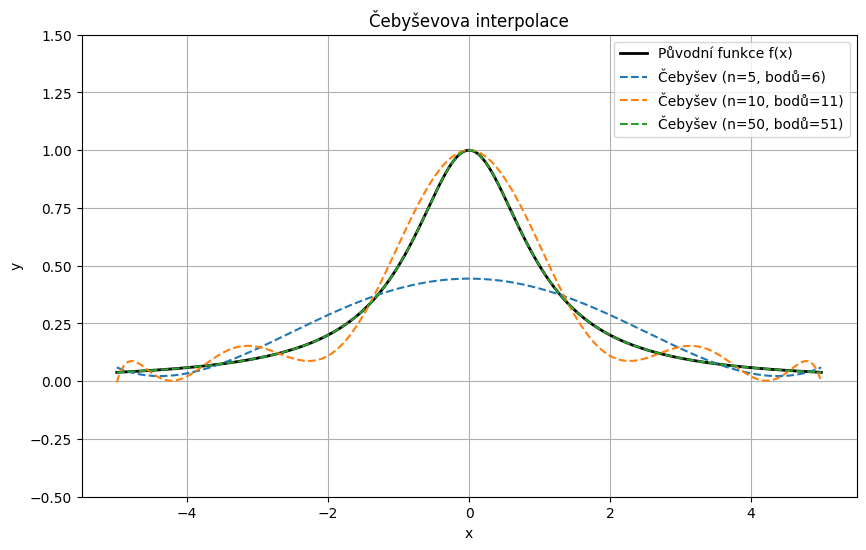

In [14]:
def f(x):
    return 1 / (1 + x**2)
a, b = -5, 5
x_plot = np.linspace(a, b, 500)
plt.figure(figsize=(10, 6))
plt.plot(x_plot, f(x_plot), 'k-', linewidth=2, label='Původní funkce f(x)')
for n in [5, 10, 50]:
    fn_plot = cebysev(f, a, b, n, x_plot)
    plt.plot(x_plot, fn_plot, '--', label=f'Čebyšev (n={n}, bodů={n+1})')

plt.title('Čebyševova interpolace')
plt.xlabel('x')
plt.ylabel('y')
plt.ylim(-0.5, 1.5)
plt.legend()
plt.grid(True)
plt.show()